# Eventos con StatsBomb Open Data: la final del Mundial 2022

Cada pase, tiro y presión del partido, con coordenadas. `analista` los descarga una vez (quedan en la caché) y los pasa a un esquema común en metros, con el origen en el centro de la cancha.

> Datos: [StatsBomb Open Data](https://github.com/statsbomb/open-data), uso educativo y de investigación citando a Hudl StatsBomb.

In [1]:
import matplotlib.pyplot as plt

from analista import Partido
from analista import graficos as gr
from analista.datos import statsbomb as sb

sb.competiciones().query("competicion == 'FIFA World Cup'")

,competicion_id,temporada_id,competicion,temporada,pais,genero
30,43,106,FIFA World Cup,2022,International,male
31,43,3,FIFA World Cup,2018,International,male
32,43,55,FIFA World Cup,1990,International,male
33,43,54,FIFA World Cup,1986,International,male
34,43,51,FIFA World Cup,1974,International,male
35,43,272,FIFA World Cup,1970,International,male
36,43,270,FIFA World Cup,1962,International,male
37,43,269,FIFA World Cup,1958,International,male


In [2]:
partidos = sb.partidos(43, 106)          # Mundial 2022
partidos.tail(3)

,partido_id,fecha,local,visitante,goles_local,goles_visitante,fase,estadio,competicion,temporada
61,3869552,2022-12-14,France,Morocco,2,0,Semi-finals,Al Bayt Stadium,FIFA World Cup,2022
62,3869684,2022-12-17,Croatia,Morocco,2,1,3rd Place Final,Sheikh Khalifa International Stadium,FIFA World Cup,2022
63,3869685,2022-12-18,Argentina,France,3,3,Final,Lusail Stadium,FIFA World Cup,2022


In [3]:
final = Partido.statsbomb(3869685, 43, 106)
final

<Partido Argentina vs France · StatsBomb Open Data · 4407 eventos>

## Resumen por equipo
`A` es el local según StatsBomb (Argentina) y `B` el visitante.

In [4]:
import pandas as pd

r = final.resumen()
pd.DataFrame(r["por_equipo"]).rename(columns=final.nombres)

,Argentina,France
goles,3.000,3.000
xg,2.760,2.270
xg_modelo,3.030,2.180
tiros,20.000,10.000
tiros_al_arco,10.000,5.000
xg_por_tiro,0.138,0.227
pases,693.000,570.000
precision_pases,80.800,76.100
pases_progresivos,43.000,21.000
posesion,54.200,45.800


## xG: el de StatsBomb y el modelo propio
El modelo de `analista` es una regresión logística entrenada con 9.817 tiros de la Premier League 2015/16 (distancia, ángulo, cabeza, balón parado, presión, defensores en el cono y posición del arquero). En 4.709 tiros sin penales de torneos internacionales predice 434,7 goles frente a 435 reales.

In [5]:
t = final.tiros()
t[["minuto", "equipo_nombre", "jugador", "resultado", "xg", "xg_modelo"]].sort_values("xg", ascending=False).head(8)

,minuto,equipo_nombre,jugador,resultado,xg,xg_modelo
770,22,Argentina,Lionel Messi,Goal,0.783500,0.780000
2927,79,France,Kylian Mbappé,Goal,0.783500,0.780000
4202,117,France,Kylian Mbappé,Goal,0.783500,0.780000
4069,107,Argentina,Lionel Messi,Goal,0.488404,0.640264
1177,35,Argentina,Ángel Di María,Goal,0.303409,0.278890
4336,122,France,Randal Kolo,Saved,0.277514,0.194733
3929,104,Argentina,Lautaro Martínez,Blocked,0.232606,0.179885
3969,105,Argentina,Lautaro Martínez,Off T,0.140292,0.234988


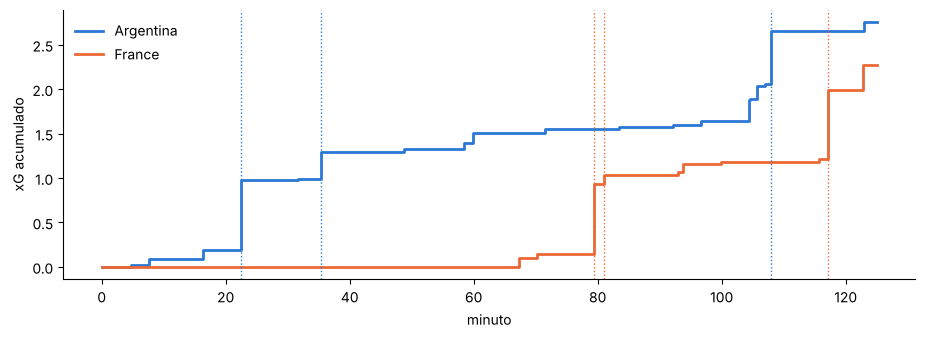

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.5))
gr.flujo_xg(final, ax=ax);

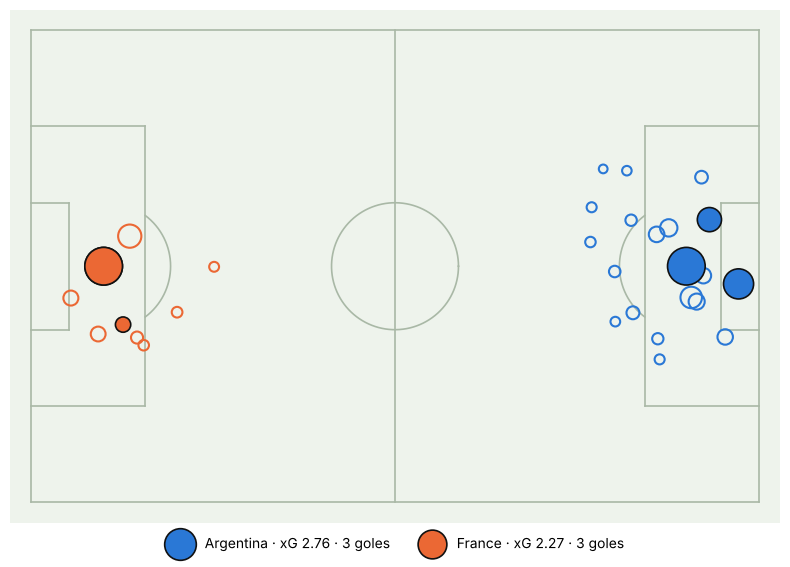

In [7]:
gr.tiros(final);

## Redes de pases hasta el primer cambio

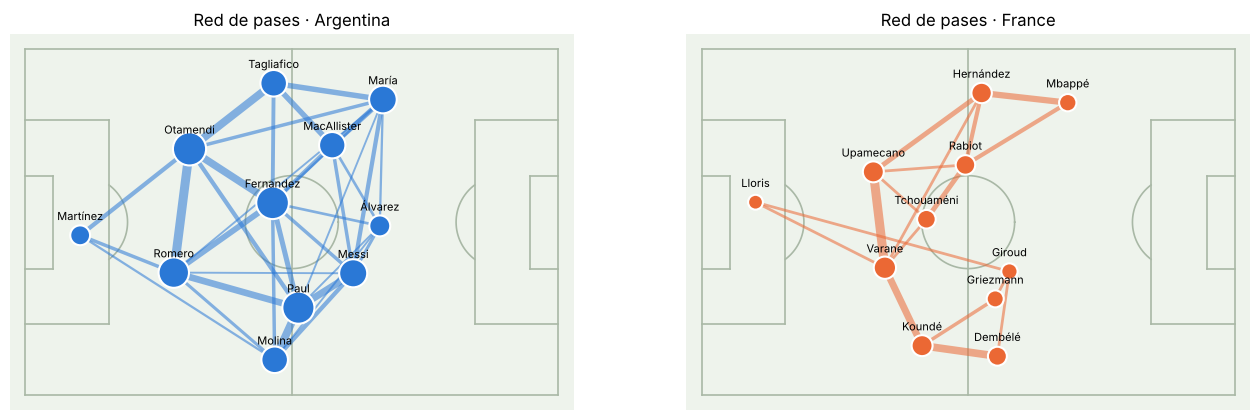

In [8]:
fig, axs = plt.subplots(1, 2, figsize=(16, 6))
gr.red_de_pases(final, "A", ax=axs[0])
gr.red_de_pases(final, "B", ax=axs[1]);

## Reporte HTML
Un archivo autocontenido para compartir (el mismo que genera el panel en la pestaña *Datos de partidos*).

In [9]:
final.reporte("final_mundial_2022.html")

PosixPath('final_mundial_2022.html')